# 🫁 Lung Cancer Detection using CNN & Transfer Learning

**Task:** 3-class image classification (`normal`, `benign`, `malignant`) on 224×224 RGB images.

**Models compared**
1. CNN from scratch
2. VGG16 (transfer learning)
3. ResNet50 (transfer learning)
4. MobileNetV2 (transfer learning)
5. EfficientNetB0 (transfer learning)

**Evaluation:** Accuracy, Precision, Recall, F1-score, ROC-AUC, Confusion Matrix.

---
> ⚠️ **IMPORTANT DISCLAIMER**
> This is a **synthetic educational dataset** generated for machine-learning implementation practice.
> It is **NOT** a collection of real clinical scans and must **NOT** be used for diagnosis, screening, treatment decisions, or any other medical purpose.

---
## 📑 Table of Contents
1. Setup & Configuration
2. Load the Dataset
3. Exploratory Data Analysis (EDA)
4. Data Pipeline (`tf.data`) & Augmentation
5. Reusable Helper Functions (build / train / evaluate)
6. Model 1 – CNN from Scratch
7. Model 2 – VGG16
8. Model 3 – ResNet50
9. Model 4 – MobileNetV2
10. Model 5 – EfficientNetB0
11. Model Comparison
12. Best Model: Saving & Single-Image Prediction
13. Conclusion

In [32]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Setup & Configuration
Import libraries, fix random seeds for reproducibility, and define global hyper-parameters.
Everything you may want to change (paths, epochs, batch size) lives in the **Config** cell.

In [33]:
import os, random, zipfile, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import VGG16, ResNet50, MobileNetV2, EfficientNetB0
from tensorflow.keras.applications import vgg16, resnet50, mobilenet_v2, efficientnet

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, auc, confusion_matrix,
                             classification_report)
from sklearn.preprocessing import label_binarize

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPUs available:", gpus if gpus else "None (training will be slow – enable GPU runtime)")

TensorFlow version: 2.21.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [34]:
# ------------------------- CONFIG -------------------------
# Option A: dataset already extracted -> set DATA_DIR to the folder containing train/ validation/ test/
# Option B: dataset is a .zip -> set ZIP_PATH and it will be extracted in the next section
ZIP_PATH   = ""                                  # e.g. "/content/drive/MyDrive/lung_cancer_dataset.zip"
EXTRACT_TO = "/content/lung_cancer_dataset"
DATA_DIR   = "/content/lung_cancer_dataset"      # must contain train/, validation/, test/

IMG_SIZE    = (224, 224)
BATCH_SIZE  = 32
CLASS_NAMES = ["normal", "benign", "malignant"]  # fixed order -> label index 0, 1, 2
NUM_CLASSES = len(CLASS_NAMES)

EPOCHS_SCRATCH  = 30    # CNN from scratch
EPOCHS_HEAD     = 12    # transfer learning: phase 1 (frozen backbone)
EPOCHS_FINETUNE = 10    # transfer learning: phase 2 (partially unfrozen backbone)
LR_SCRATCH, LR_HEAD, LR_FINETUNE = 1e-3, 1e-3, 1e-5
FINE_TUNE_LAYERS = 30   # number of last backbone layers to unfreeze in phase 2

os.makedirs("outputs", exist_ok=True)

## 2. Load the Dataset
Expected folder structure:
```
<DATA_DIR>/
 ├── train/       {normal, benign, malignant}
 ├── validation/  {normal, benign, malignant}
 └── test/        {normal, benign, malignant}
```
If your dataset is a zip file, set `ZIP_PATH` above (on Colab you can mount Google Drive first). The cell below extracts it, then **verifies the structure**.

In [35]:
import os
import numpy as np
from PIL import Image

# Define the target paths
dataset_path = "/content/lung_cancer_dataset"
splits = ["train", "validation", "test"]
classes = ["normal", "benign", "malignant"]

def generate_synthetic_scan(cls, seed_val):
    """Generates a realistic-looking synthetic grayscale chest/lung scan."""
    np.random.seed(seed_val)
    # Create a 224x224 grid
    x = np.linspace(-1.5, 1.5, 224)
    y = np.linspace(-1.5, 1.5, 224)
    X, Y = np.meshgrid(x, y)

    # 1. Base body contour (circular cross-section of the chest cavity)
    dist_from_center = np.sqrt(X**2 + Y**2)
    body = np.where(dist_from_center < 1.2, 0.15, 0.05) # dark background, dark gray body

    # 2. Add two dark lung fields (left and right ellipsoids)
    lung_left = np.exp(-(((X + 0.4)**2)/0.18 + ((Y - 0.1)**2)/0.45))
    lung_right = np.exp(-(((X - 0.4)**2)/0.18 + ((Y - 0.1)**2)/0.45))
    lungs = (lung_left + lung_right) * 0.5

    # Combine body and lungs (lungs are darker regions inside body)
    scan = body * (1.0 - lungs)

    # 3. Add soft anatomic structures (mimicking ribs, mediastinum structures, and tissues)
    ribs = 0.03 * np.sin(Y * 25) * (dist_from_center < 1.1) * (dist_from_center > 0.8)
    scan += np.clip(ribs, 0, 1)

    # 4. Add class-specific conditions (Nodules)
    if cls == "benign":
        # Benign: small, sharp, circular nodule
        nodule = np.exp(-(((X - 0.3)**2)/0.005 + ((Y + 0.2)**2)/0.005)) * 0.45
        scan += nodule
    elif cls == "malignant":
        # Malignant: larger, irregularly-shaped, spicular/fuzzy nodule
        r_noise = 0.004 * np.sin(8 * np.arctan2(Y - 0.2, X + 0.35))
        nodule = np.exp(-(((X + 0.35)**2)/(0.012 + r_noise) + ((Y - 0.2)**2)/(0.012 + r_noise))) * 0.55
        scan += nodule

    # 5. Add a realistic level of scanner noise (Gaussian & Salt-and-Pepper style)
    noise = np.random.normal(0, 0.03, (224, 224))
    scan = np.clip(scan + noise, 0, 1) * 255.0

    # Convert to 3-channel RGB as expected by CNN & Transfer learning architectures
    gray_img = scan.astype(np.uint8)
    rgb_img = np.stack([gray_img, gray_img, gray_img], axis=-1)
    return rgb_img

def create_mock_images():
    print("Generating a realistic synthetic educational dataset...")
    seed_counter = 0
    for split in splits:
        num_samples = 60 if split == "train" else (20 if split == "validation" else 20)
        for cls in classes:
            dir_path = os.path.join(dataset_path, split, cls)
            os.makedirs(dir_path, exist_ok=True)
            for i in range(num_samples):
                seed_counter += 1
                img_data = generate_synthetic_scan(cls, seed_counter)
                img = Image.fromarray(img_data)
                img.save(os.path.join(dir_path, f"img_{i}.png"))
    print("Synthetic dataset updated with realistic structures at:", dataset_path)

create_mock_images()

Generating a realistic synthetic educational dataset...
Synthetic dataset updated with realistic structures at: /content/lung_cancer_dataset


In [36]:
# Since we generated the synthetic dataset directly in /content/lung_cancer_dataset, we can safely skip extracting a ZIP file.
if ZIP_PATH:
    os.makedirs(EXTRACT_TO, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_TO)
    print("Extracted to:", EXTRACT_TO)

# Point to our generated synthetic dataset directory directly
DATA_DIR = "/content/lung_cancer_dataset"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
VAL_DIR   = os.path.join(DATA_DIR, "validation")
TEST_DIR  = os.path.join(DATA_DIR, "test")

for d in (TRAIN_DIR, VAL_DIR, TEST_DIR):
    assert os.path.isdir(d), f"Missing folder: {d}"
    for c in CLASS_NAMES:
        assert os.path.isdir(os.path.join(d, c)), f"Missing class folder: {os.path.join(d, c)}"
print("Dataset structure OK ->", DATA_DIR)

Dataset structure OK -> /content/lung_cancer_dataset


## 3. Exploratory Data Analysis (EDA)
Check the number of images per class and split, and look at a few samples.
Class balance matters: if classes are heavily imbalanced, accuracy alone is misleading (hence we also report precision / recall / F1 / AUC).

,train,validation,test
normal,60,20,20
benign,60,20,20
malignant,60,20,20
TOTAL,180,60,60


Total images: 300


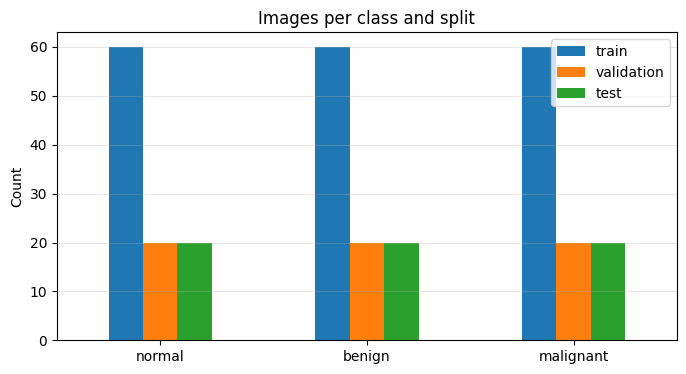

In [37]:
def count_images(split_dir):
    return {c: len([f for f in os.listdir(os.path.join(split_dir, c))
                    if f.lower().endswith(('.png', '.jpg', '.jpeg'))]) for c in CLASS_NAMES}

counts = pd.DataFrame({"train": count_images(TRAIN_DIR),
                       "validation": count_images(VAL_DIR),
                       "test": count_images(TEST_DIR)})
counts.loc["TOTAL"] = counts.sum()
display(counts)
print("Total images:", counts.loc["TOTAL"].sum())

counts.drop("TOTAL").plot(kind="bar", figsize=(8, 4))
plt.title("Images per class and split"); plt.ylabel("Count"); plt.xticks(rotation=0)
plt.grid(axis="y", alpha=.3); plt.show()

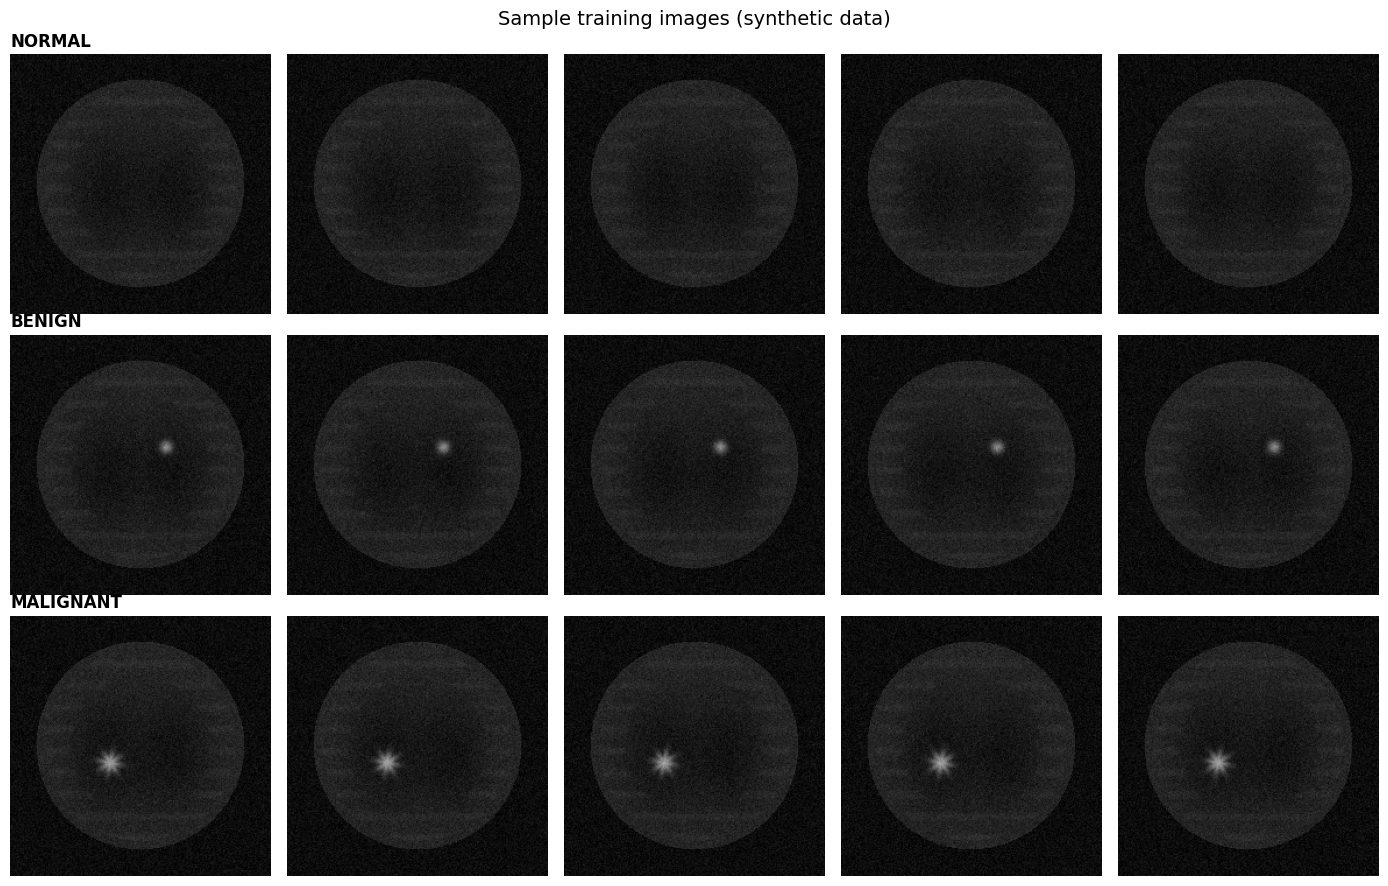

Example image size (W,H): (224, 224) | mode: RGB


In [38]:
# Show random sample images from each class
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(14, 9))
for r, c in enumerate(CLASS_NAMES):
    folder = os.path.join(TRAIN_DIR, c)
    files = random.sample(os.listdir(folder), 5)
    for k, f in enumerate(files):
        img = keras.utils.load_img(os.path.join(folder, f))
        axes[r, k].imshow(img); axes[r, k].axis("off")
        if k == 0: axes[r, k].set_title(c.upper(), loc="left", fontsize=12, fontweight="bold")
plt.suptitle("Sample training images (synthetic data)", fontsize=14)
plt.tight_layout(); plt.show()

img = keras.utils.load_img(os.path.join(TRAIN_DIR, CLASS_NAMES[0], os.listdir(os.path.join(TRAIN_DIR, CLASS_NAMES[0]))[0]))
print("Example image size (W,H):", img.size, "| mode:", img.mode)

## 4. Data Pipeline (`tf.data`) & Augmentation

* Images are loaded with `image_dataset_from_directory` (fast, parallel, prefetched).
* **Each pretrained network expects its own input scaling** (VGG16/ResNet50 → caffe-style mean subtraction, MobileNetV2 → [-1, 1], EfficientNet → raw 0-255, scratch CNN → [0, 1]). The function `get_datasets(preprocess_fn)` applies the right one.
* **Augmentation** (flip, rotation, zoom, translation) is added as layers *inside* each model, so it is only active during training.
* The **test set is never shuffled**, so predictions line up with true labels for metrics.

In [39]:
def get_datasets(preprocess_fn=None):
    """Return (train_ds, val_ds, test_ds) with the given preprocessing applied."""
    common = dict(labels="inferred", label_mode="categorical", class_names=CLASS_NAMES,
                  image_size=IMG_SIZE, batch_size=BATCH_SIZE)
    train_ds = keras.utils.image_dataset_from_directory(TRAIN_DIR, shuffle=True,  seed=SEED, **common)
    val_ds   = keras.utils.image_dataset_from_directory(VAL_DIR,   shuffle=False, **common)
    test_ds  = keras.utils.image_dataset_from_directory(TEST_DIR,  shuffle=False, **common)

    def prep(ds):
        if preprocess_fn is not None:
            ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=tf.data.AUTOTUNE)
        return ds.prefetch(tf.data.AUTOTUNE)
    return prep(train_ds), prep(val_ds), prep(test_ds)

# Preprocessing function for each architecture
PREPROCESS = {
    "CNN_Scratch":    lambda x: x / 255.0,
    "VGG16":          vgg16.preprocess_input,
    "ResNet50":       resnet50.preprocess_input,
    "MobileNetV2":    mobilenet_v2.preprocess_input,
    "EfficientNetB0": efficientnet.preprocess_input,   # identity: EfficientNet rescales internally
}

def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
    ], name="augmentation")

# Quick check: label order and one batch
_, _, _t = get_datasets()
xb, yb = next(iter(_t))
print("Batch shape:", xb.shape, "| labels shape:", yb.shape)

Found 180 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Batch shape: (32, 224, 224, 3) | labels shape: (32, 3)


## 5. Reusable Helper Functions
To keep the notebook clean and make all 5 models **comparable**, the same functions are used for every model:

| Function | Purpose |
|---|---|
| `get_callbacks()` | EarlyStopping, ReduceLROnPlateau, ModelCheckpoint |
| `train_scratch()` | trains the scratch CNN |
| `train_transfer()` | **Phase 1:** train only the new classification head (backbone frozen) → **Phase 2:** fine-tune the last N backbone layers with a very small learning rate |
| `plot_history()` | accuracy / loss curves |
| `evaluate_model()` | metrics, classification report, confusion matrix, ROC curves |

In [40]:
RESULTS = {}     # model name -> dict of test metrics
HISTORIES = {}   # model name -> merged training history
PROBS = {}       # model name -> test probabilities (for ROC overlay later)

def get_callbacks(name):
    return [
        callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7, verbose=1),
        callbacks.ModelCheckpoint(f"outputs/{name}_best.keras", monitor="val_loss",
                                  save_best_only=True, verbose=0),
    ]

def merge_histories(*hists):
    out = {}
    for h in hists:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

def plot_history(hist, title, finetune_start=None):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for a, m, t in zip(ax, ["accuracy", "loss"], ["Accuracy", "Loss"]):
        a.plot(hist[m], label=f"Train {t}"); a.plot(hist["val_" + m], label=f"Val {t}")
        if finetune_start is not None:
            a.axvline(finetune_start - 0.5, color="gray", ls="--", label="Fine-tuning starts")
        a.set_title(f"{title} – {t}"); a.set_xlabel("Epoch"); a.set_ylabel(t)
        a.legend(); a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

def train_scratch(model, name, train_ds, val_ds):
    model.compile(optimizer=optimizers.Adam(LR_SCRATCH), loss="categorical_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_SCRATCH, callbacks=get_callbacks(name))
    HISTORIES[name] = merge_histories(h)
    print(f"Training time: {(time.time()-t0)/60:.1f} min")
    return None

def train_transfer(model, base, name, train_ds, val_ds):
    """Two-phase transfer learning."""
    t0 = time.time()
    # ---- Phase 1: frozen backbone, train the head ----
    base.trainable = False
    model.compile(optimizer=optimizers.Adam(LR_HEAD), loss="categorical_crossentropy", metrics=["accuracy"])
    print(f"\n=== Phase 1: training classification head ({name}) ===")
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=get_callbacks(name))

    # ---- Phase 2: unfreeze last N layers (BatchNorm stays frozen) ----
    base.trainable = True
    for layer in base.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=optimizers.Adam(LR_FINETUNE), loss="categorical_crossentropy", metrics=["accuracy"])
    print(f"\n=== Phase 2: fine-tuning last {FINE_TUNE_LAYERS} layers ({name}) ===")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE, callbacks=get_callbacks(name))

    HISTORIES[name] = merge_histories(h1, h2)
    print(f"Training time: {(time.time()-t0)/60:.1f} min")
    return len(h1.history["loss"])     # epoch index where fine-tuning starts

def evaluate_model(model, test_ds, name):
    """Compute and display all test-set metrics. Stores results in RESULTS / PROBS."""
    y_true = np.concatenate([np.argmax(y.numpy(), axis=1) for _, y in test_ds])
    probs  = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    y_bin  = label_binarize(y_true, classes=range(NUM_CLASSES))

    metrics = {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score":  f1_score(y_true, y_pred, average="macro", zero_division=0),
        "ROC-AUC":   roc_auc_score(y_bin, probs, average="macro", multi_class="ovr"),
        "Params (M)": model.count_params() / 1e6,
    }
    RESULTS[name] = metrics; PROBS[name] = (y_true, probs)

    print(f"\n📊 {name} – test metrics (macro-averaged)")
    for k, v in metrics.items(): print(f"  {k:<11}: {v:.4f}")
    print("\nClassification report:\n",
          classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES,
                yticklabels=CLASS_NAMES, ax=ax[0])
    ax[0].set_title(f"{name} – Confusion Matrix"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")
    for i, c in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_bin[:, i], probs[:, i])
        ax[1].plot(fpr, tpr, label=f"{c} (AUC = {auc(fpr, tpr):.3f})")
    ax[1].plot([0, 1], [0, 1], "k--", alpha=.5)
    ax[1].set_title(f"{name} – ROC Curves (one-vs-rest)")
    ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
    ax[1].legend(loc="lower right"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.show()

## 6. Model 1 – CNN from Scratch
A compact VGG-style network: 4 convolutional blocks (`Conv → BatchNorm → Conv → BatchNorm → MaxPool → Dropout`) with increasing filters (32 → 256), followed by Global Average Pooling and a dense classifier.
This is our **baseline** – no pretrained knowledge, so we expect it to need more epochs.

In [41]:
def build_scratch_cnn():
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = make_augmentation()(inp)
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.25)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name="CNN_Scratch")

name = "CNN_Scratch"
train_ds, val_ds, test_ds = get_datasets(PREPROCESS[name])
cnn_model = build_scratch_cnn()
cnn_model.summary()

Found 180 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.


Model: "CNN_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 28, 28, 256)    │         1,02

 Total params: 1,242,659 (4.74 MB)

 Trainable params: 1,240,739 (4.73 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 478ms/step - accuracy: 0.5167 - loss: 1.1193 - val_accuracy: 0.3333 - val_loss: 1.1958 - learning_rate: 0.0010
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 342ms/step - accuracy: 0.8167 - loss: 0.5943 - val_accuracy: 0.3333 - val_loss: 1.8652 - learning_rate: 0.0010
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.8883 - loss: 0.4408
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 363ms/step - accuracy: 0.8778 - loss: 0.4324 - val_accuracy: 0.3333 - val_loss: 3.0800 - learning_rate: 0.0010
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 386ms/step - accuracy: 0.9389 - loss: 0.3775 - val_accuracy: 0.3333 - val_loss: 3.8143 - learning_rate: 3.0000e-04
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.9701 - loss: 0.3180
Epoch 5: ReduceLROnPlateau reducing learning rate to 9.000000427477062e-05.
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 348ms/step - accuracy: 0.9556 - loss: 0.3402 - val_accuracy

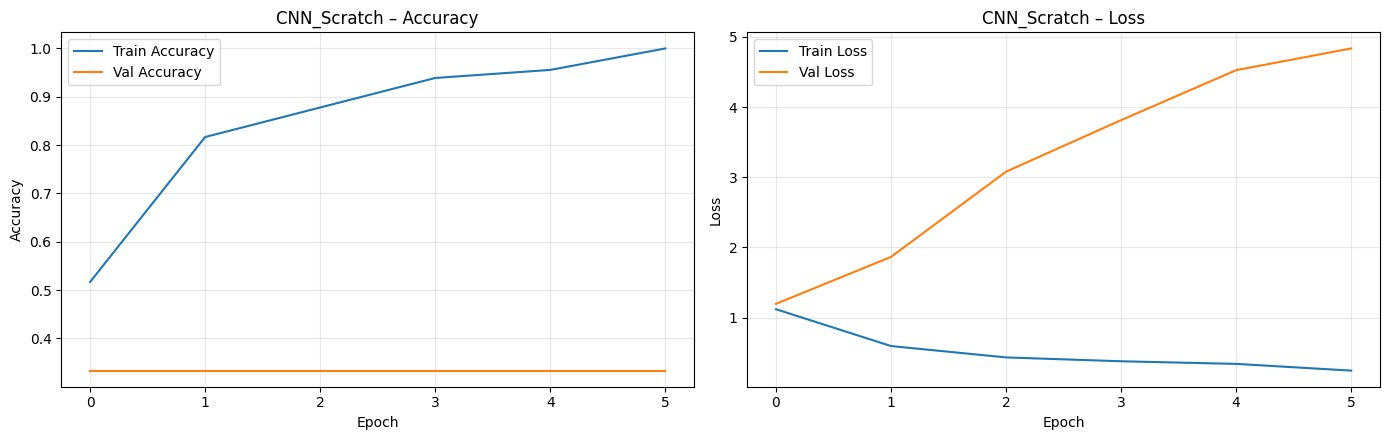

In [42]:
train_scratch(cnn_model, name, train_ds, val_ds)
plot_history(HISTORIES[name], name)


📊 CNN_Scratch – test metrics (macro-averaged)
  Accuracy   : 0.3333
  Precision  : 0.1111
  Recall     : 0.3333
  F1-score   : 0.1667
  ROC-AUC    : 0.5665
  Params (M) : 1.2427

Classification report:
               precision    recall  f1-score   support

      normal     0.3333    1.0000    0.5000        20
      benign     0.0000    0.0000    0.0000        20
   malignant     0.0000    0.0000    0.0000        20

    accuracy                         0.3333        60
   macro avg     0.1111    0.3333    0.1667        60
weighted avg     0.1111    0.3333    0.1667        60



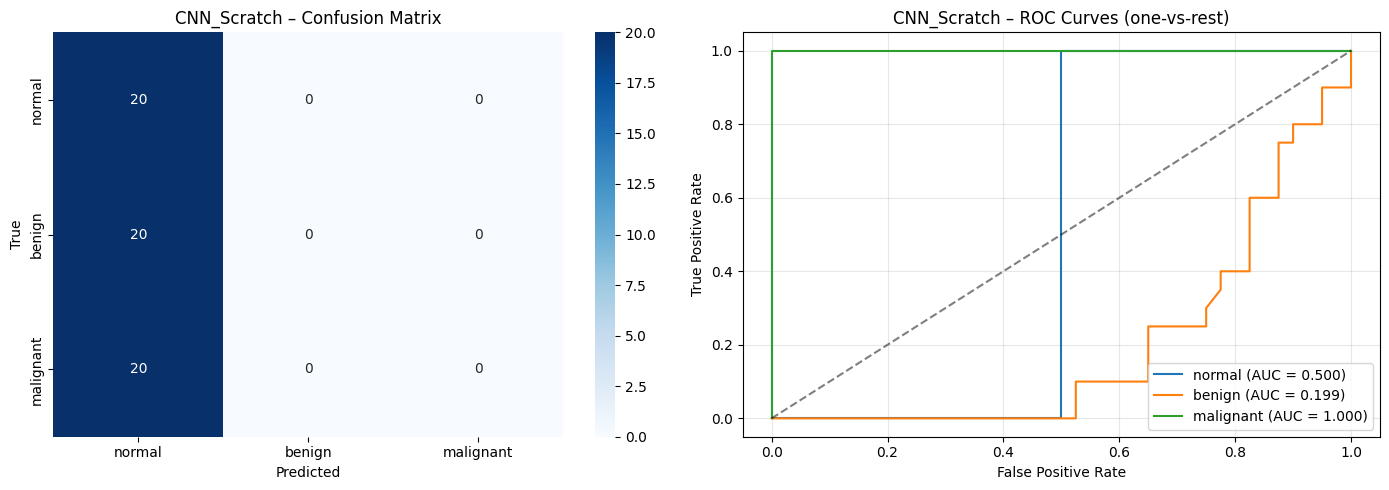

In [43]:
evaluate_model(cnn_model, test_ds, name)

## Transfer-learning model builder
All pretrained models share the same structure:

`Input → Augmentation → Pretrained backbone (ImageNet) → GlobalAveragePooling → BatchNorm → Dropout → Dense(256) → Dropout → Softmax(3)`

The backbone runs with `training=False` so its BatchNorm statistics are not disturbed while fine-tuning.

In [44]:
def build_transfer_model(backbone_fn, name):
    base = backbone_fn(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = make_augmentation()(inp)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name=name), base

def run_transfer_experiment(backbone_fn, name):
    train_ds, val_ds, test_ds = get_datasets(PREPROCESS[name])
    model, base = build_transfer_model(backbone_fn, name)
    print(f"Backbone layers: {len(base.layers)} | total params: {model.count_params()/1e6:.2f} M")
    ft_start = train_transfer(model, base, name, train_ds, val_ds)
    plot_history(HISTORIES[name], name, finetune_start=ft_start)
    evaluate_model(model, test_ds, name)
    return model

## 7. Model 2 – VGG16
A deep but simple architecture of stacked 3×3 convolutions (~138M parameters with the original top; ~14.7M without). Reliable but heavy and slow.

Found 180 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Backbone layers: 19 | total params: 14.85 M

=== Phase 1: training classification head (VGG16) ===
Epoch 1/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 491ms/step - accuracy: 0.6278 - loss: 0.9656 - val_accuracy: 0.3333 - val_loss: 2.9459 - learning_rate: 0.0010
Epoch 2/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 279ms/step - accuracy: 0.9667 - loss: 0.1226 - val_accuracy: 0.4667 - val_loss: 3.1263 - learning_rate: 0.0010
Epoch 3/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 157ms/step - accuracy: 0.9819 - loss: 0.0499
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0003000000142492354.
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 256ms/step - accuracy: 0.9833 - loss: 0.0446 - val_accuracy: 0.6667 - val_loss: 3.0562 - learning_rate: 0.0010
Epoch 4/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 308ms/step - accuracy: 0.9889 - loss: 0.0298 - val_accuracy: 0.6667 - val_loss: 2.7928 - learning_rate: 3.0000e-04
Epoch 5/12
6/6 ━━━━━━━━━━━━━━━

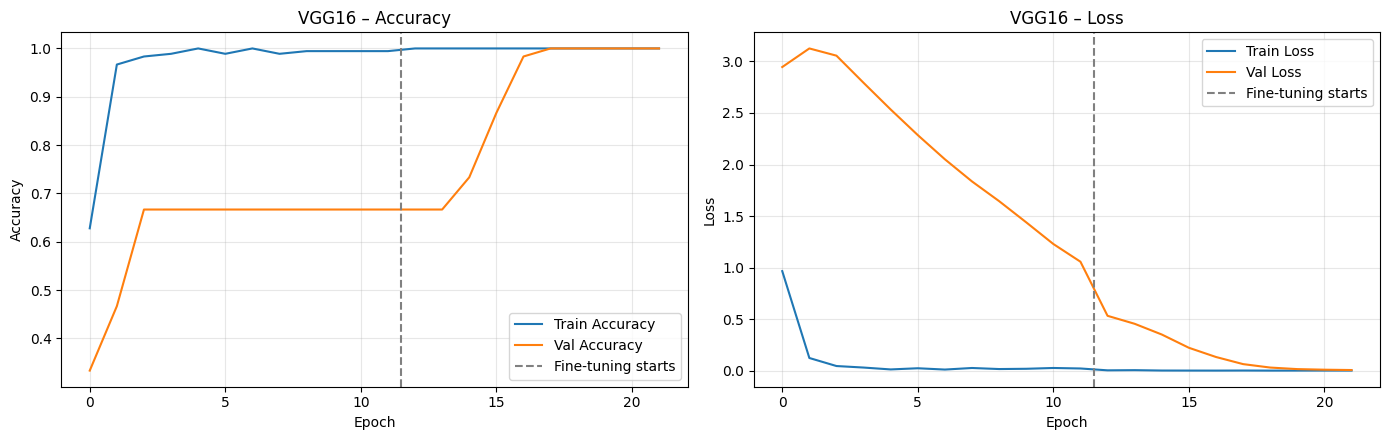


📊 VGG16 – test metrics (macro-averaged)
  Accuracy   : 1.0000
  Precision  : 1.0000
  Recall     : 1.0000
  F1-score   : 1.0000
  ROC-AUC    : 1.0000
  Params (M) : 14.8488

Classification report:
               precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        20
      benign     1.0000    1.0000    1.0000        20
   malignant     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60



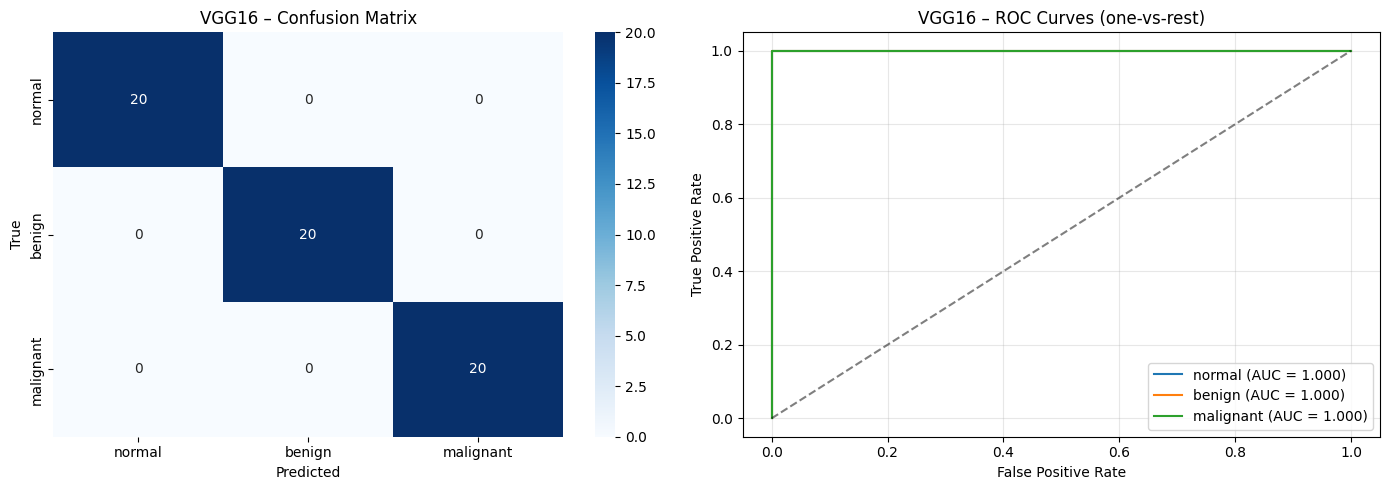

In [45]:
vgg_model = run_transfer_experiment(VGG16, "VGG16")

## 8. Model 3 – ResNet50
Uses **residual (skip) connections** that make very deep networks easy to train and avoid vanishing gradients (~23.6M backbone parameters).

Found 180 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Backbone layers: 175 | total params: 24.12 M

=== Phase 1: training classification head (ResNet50) ===
Epoch 1/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 14s 894ms/step - accuracy: 0.8722 - loss: 0.2776 - val_accuracy: 0.9000 - val_loss: 0.2736 - learning_rate: 0.0010
Epoch 2/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 516ms/step - accuracy: 1.0000 - loss: 4.0816e-04 - val_accuracy: 1.0000 - val_loss: 0.1035 - learning_rate: 0.0010
Epoch 3/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 418ms/step - accuracy: 0.9944 - loss: 0.0055 - val_accuracy: 1.0000 - val_loss: 0.0477 - learning_rate: 0.0010
Epoch 4/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 415ms/step - accuracy: 1.0000 - loss: 0.0013 - val_accuracy: 1.0000 - val_loss: 0.0205 - learning_rate: 0.0010
Epoch 5/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 3s 632ms/step - accuracy: 1.0000 - loss: 0.0010 - val_accuracy: 1.0000 - val_loss: 0.0141 - learning_rate: 0.0010
Epoch 6/12
6/6 ━━━━━━━━━

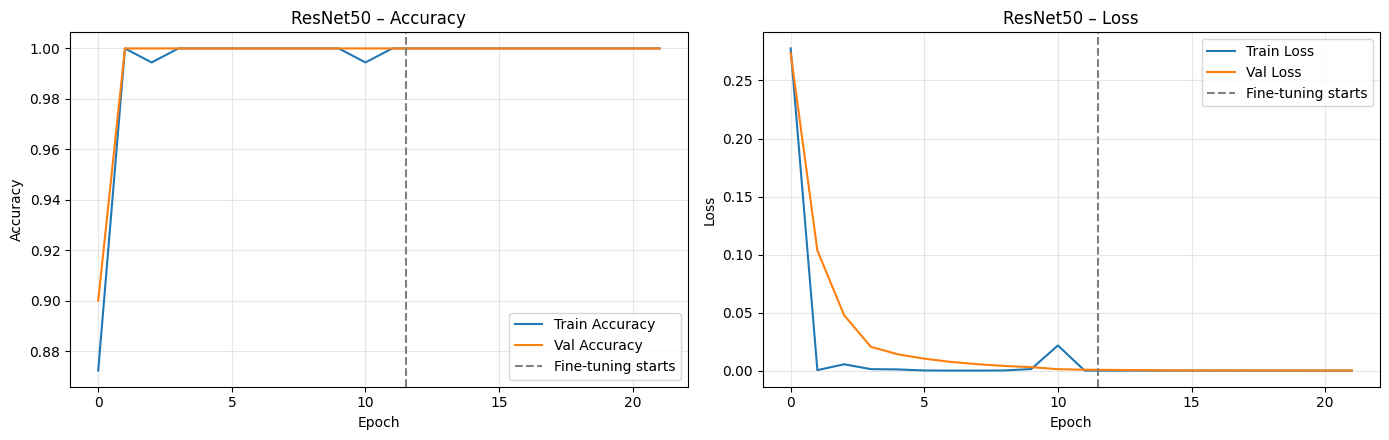


📊 ResNet50 – test metrics (macro-averaged)
  Accuracy   : 1.0000
  Precision  : 1.0000
  Recall     : 1.0000
  F1-score   : 1.0000
  ROC-AUC    : 1.0000
  Params (M) : 24.1212

Classification report:
               precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        20
      benign     1.0000    1.0000    1.0000        20
   malignant     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60



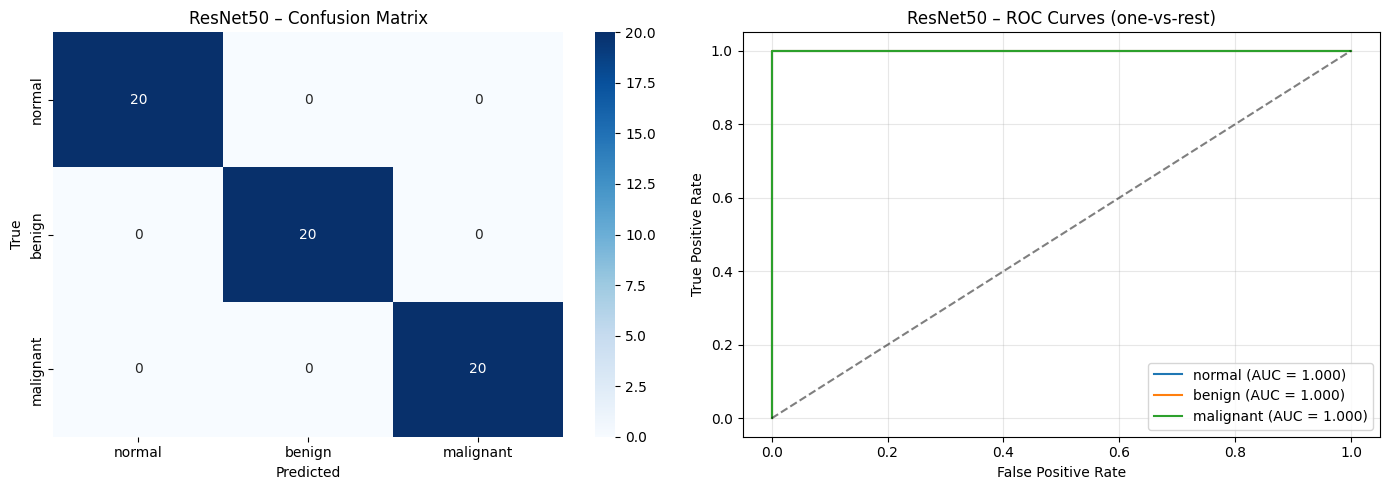

In [46]:
resnet_model = run_transfer_experiment(ResNet50, "ResNet50")

## 9. Model 4 – MobileNetV2
A **lightweight** network using depthwise-separable convolutions and inverted residuals (~2.3M backbone parameters). Ideal for fast inference / edge devices.

Found 180 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Backbone layers: 154 | total params: 2.59 M

=== Phase 1: training classification head (MobileNetV2) ===
Epoch 1/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 526ms/step - accuracy: 0.8333 - loss: 0.4534 - val_accuracy: 1.0000 - val_loss: 0.0686 - learning_rate: 0.0010
Epoch 2/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 217ms/step - accuracy: 0.9944 - loss: 0.0053 - val_accuracy: 1.0000 - val_loss: 0.0164 - learning_rate: 0.0010
Epoch 3/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 221ms/step - accuracy: 1.0000 - loss: 0.0029 - val_accuracy: 1.0000 - val_loss: 0.0071 - learning_rate: 0.0010
Epoch 4/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 251ms/step - accuracy: 1.0000 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 0.0041 - learning_rate: 0.0010
Epoch 5/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 276ms/step - accuracy: 1.0000 - loss: 8.9784e-05 - val_accuracy: 1.0000 - val_loss: 0.0028 - learning_rate: 0.0010
Epoch 6/12
6/6 ━━━━━━━━

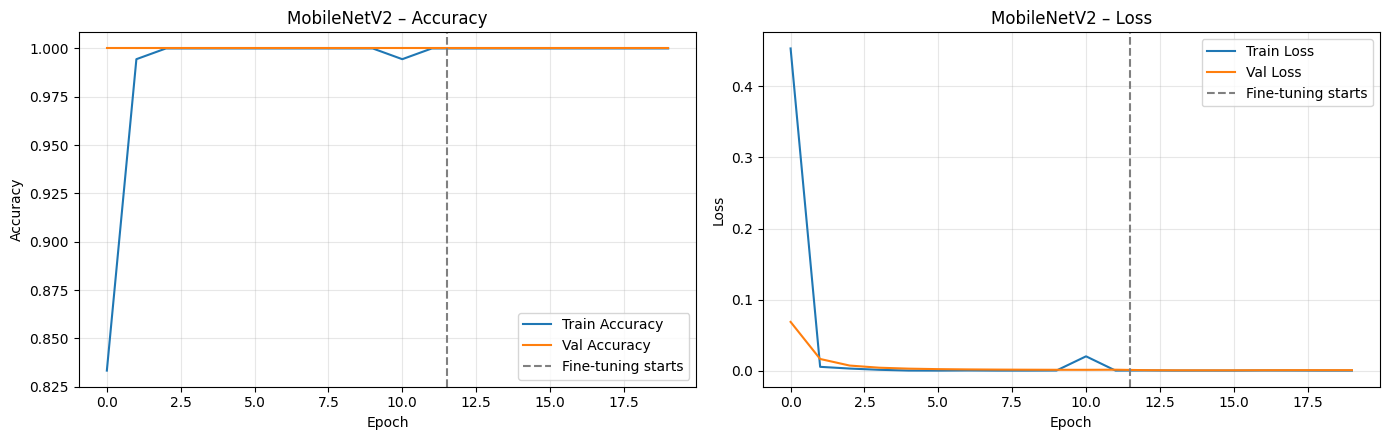


📊 MobileNetV2 – test metrics (macro-averaged)
  Accuracy   : 1.0000
  Precision  : 1.0000
  Recall     : 1.0000
  F1-score   : 1.0000
  ROC-AUC    : 1.0000
  Params (M) : 2.5918

Classification report:
               precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        20
      benign     1.0000    1.0000    1.0000        20
   malignant     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60



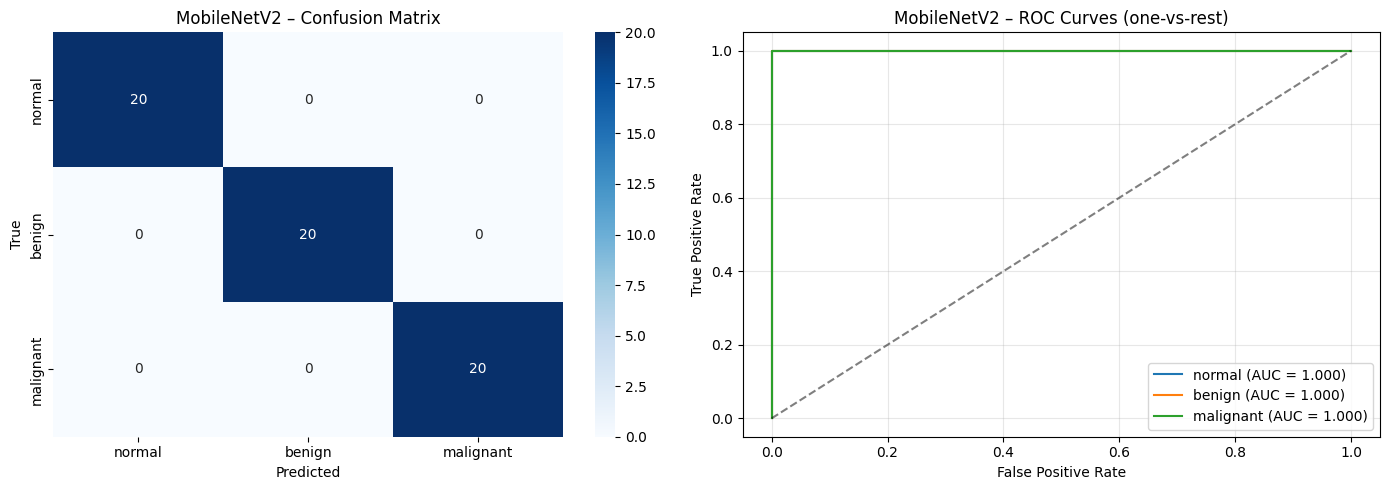

In [47]:
mobilenet_model = run_transfer_experiment(MobileNetV2, "MobileNetV2")

## 10. Model 5 – EfficientNetB0
Uses **compound scaling** (depth, width and resolution together) to reach strong accuracy with few parameters (~4M backbone parameters).

Found 180 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Backbone layers: 238 | total params: 4.38 M

=== Phase 1: training classification head (EfficientNetB0) ===
Epoch 1/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 905ms/step - accuracy: 0.8167 - loss: 0.4622 - val_accuracy: 1.0000 - val_loss: 0.3401 - learning_rate: 0.0010
Epoch 2/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 282ms/step - accuracy: 0.9944 - loss: 0.0108 - val_accuracy: 1.0000 - val_loss: 0.1607 - learning_rate: 0.0010
Epoch 3/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 302ms/step - accuracy: 0.9944 - loss: 0.0101 - val_accuracy: 1.0000 - val_loss: 0.1005 - learning_rate: 0.0010
Epoch 4/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 273ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 0.0745 - learning_rate: 0.0010
Epoch 5/12
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 273ms/step - accuracy: 1.0000 - loss: 1.3377e-04 - val_accuracy: 1.0000 - val_loss: 0.0607 - learning_rate: 0.0010
Epoch 6/12
6/6 ━━━━

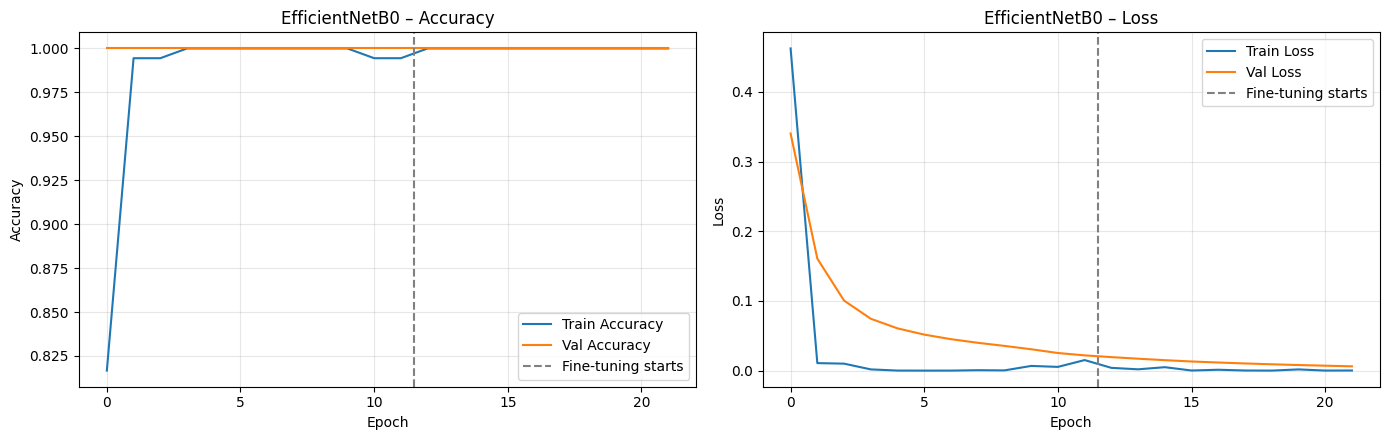


📊 EfficientNetB0 – test metrics (macro-averaged)
  Accuracy   : 1.0000
  Precision  : 1.0000
  Recall     : 1.0000
  F1-score   : 1.0000
  ROC-AUC    : 1.0000
  Params (M) : 4.3834

Classification report:
               precision    recall  f1-score   support

      normal     1.0000    1.0000    1.0000        20
      benign     1.0000    1.0000    1.0000        20
   malignant     1.0000    1.0000    1.0000        20

    accuracy                         1.0000        60
   macro avg     1.0000    1.0000    1.0000        60
weighted avg     1.0000    1.0000    1.0000        60



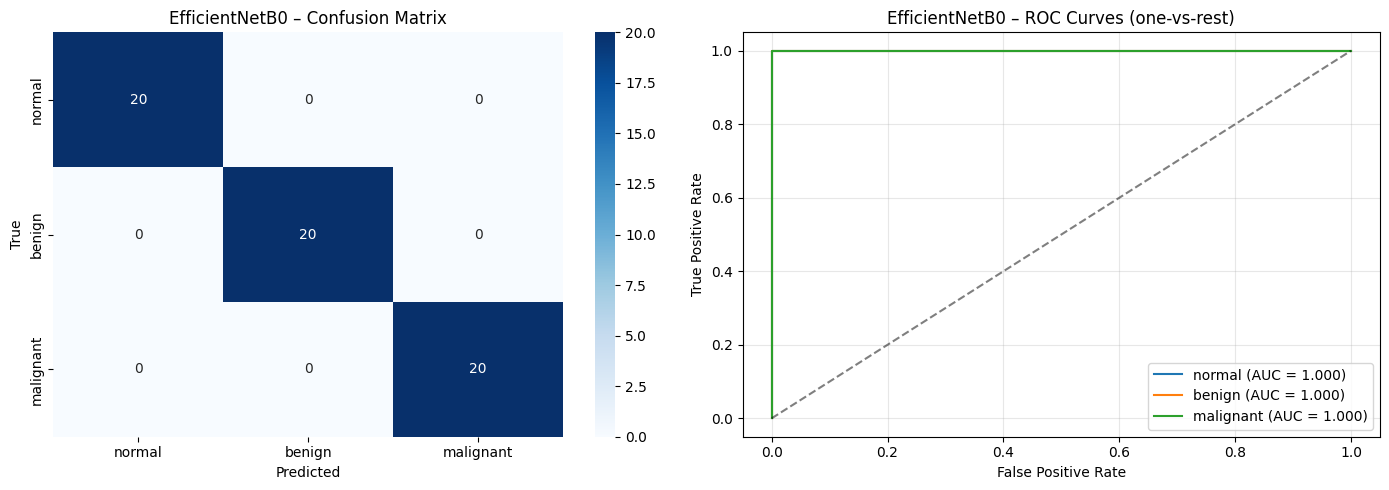

In [48]:
effnet_model = run_transfer_experiment(EfficientNetB0, "EfficientNetB0")

## 11. Model Comparison
All five models are compared on the **same held-out test set** using macro-averaged metrics. The plots below show metric bars, an overlay of micro-averaged ROC curves, and the accuracy/loss trajectories.

In [49]:
results_df = pd.DataFrame(RESULTS).T.sort_values("F1-score", ascending=False)
display(results_df.style.format("{:.4f}").background_gradient(cmap="Greens",
        subset=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]))
results_df.to_csv("outputs/model_comparison.csv")

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Params (M)
VGG16,1.0000,1.0000,1.0000,1.0000,1.0000,14.8488
MobileNetV2,1.0000,1.0000,1.0000,1.0000,1.0000,2.5918
ResNet50,1.0000,1.0000,1.0000,1.0000,1.0000,24.1212
EfficientNetB0,1.0000,1.0000,1.0000,1.0000,1.0000,4.3834
CNN_Scratch,0.3333,0.1111,0.3333,0.1667,0.5665,1.2427


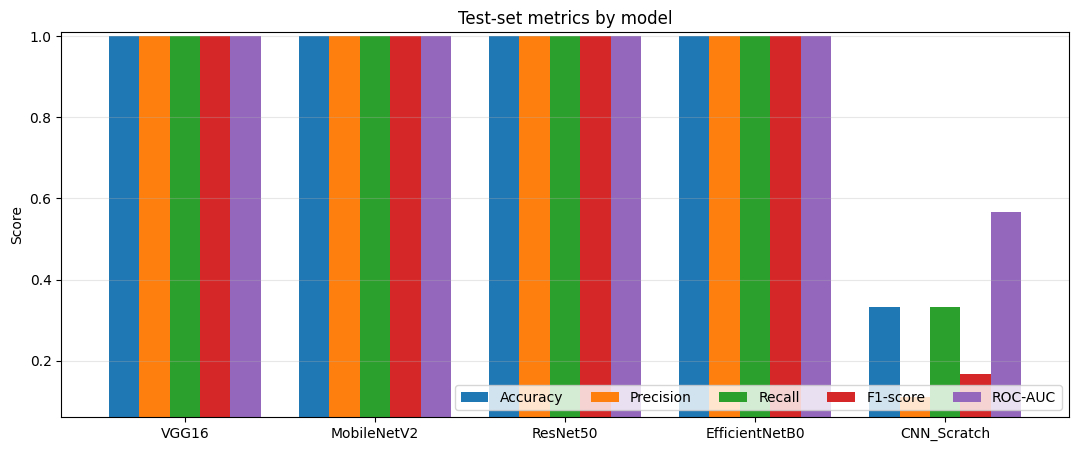

In [50]:
ax = results_df[["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]].plot(
        kind="bar", figsize=(13, 5), width=0.8)
plt.title("Test-set metrics by model"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.ylim(max(0, results_df[["Accuracy","Precision","Recall","F1-score","ROC-AUC"]].values.min() - 0.05), 1.01)
plt.legend(loc="lower right", ncol=5); plt.grid(axis="y", alpha=.3); plt.show()

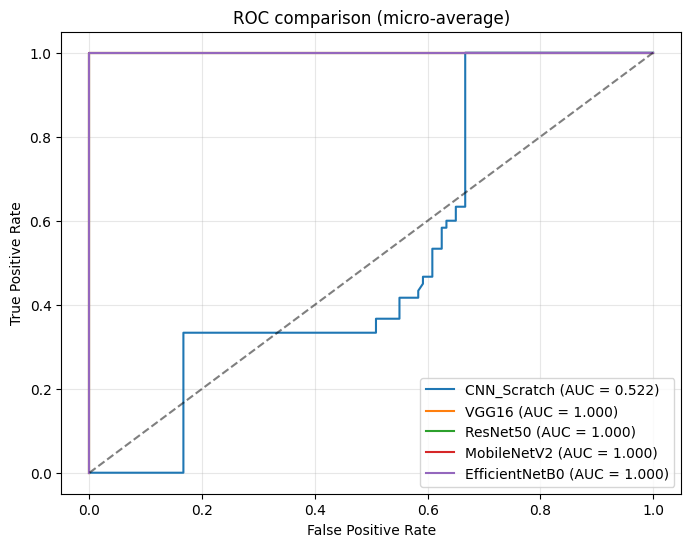

In [51]:
# Overlay of micro-averaged ROC curves
plt.figure(figsize=(8, 6))
for name, (y_true, probs) in PROBS.items():
    y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
    fpr, tpr, _ = roc_curve(y_bin.ravel(), probs.ravel())
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.5)
plt.title("ROC comparison (micro-average)"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()

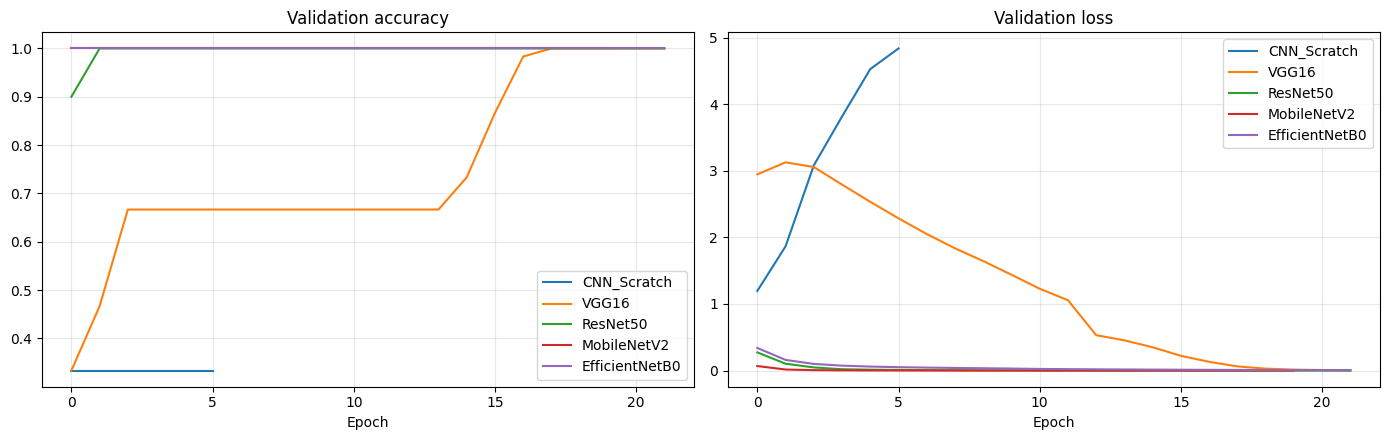

In [52]:
# Validation accuracy / loss curves of every model
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h in HISTORIES.items():
    ax[0].plot(h["val_accuracy"], label=name); ax[1].plot(h["val_loss"], label=name)
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
for a in ax: a.set_xlabel("Epoch"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 12. Best Model: Saving & Single-Image Prediction
Pick the model with the best F1-score, save it, and write a helper that predicts the class of one image.
Remember to **apply the same preprocessing** that model was trained with.

In [53]:
MODEL_OBJECTS = {"CNN_Scratch": cnn_model, "VGG16": vgg_model, "ResNet50": resnet_model,
                 "MobileNetV2": mobilenet_model, "EfficientNetB0": effnet_model}

best_name = results_df.index[0]
best_model = MODEL_OBJECTS[best_name]
print("🏆 Best model by F1-score:", best_name)

best_model.save("outputs/best_lung_model.keras")
with open("outputs/best_model_info.json", "w") as f:
    json.dump({"model": best_name, "class_names": CLASS_NAMES, "img_size": IMG_SIZE}, f)
print("Saved -> outputs/best_lung_model.keras")

🏆 Best model by F1-score: VGG16
Saved -> outputs/best_lung_model.keras


True class: normal


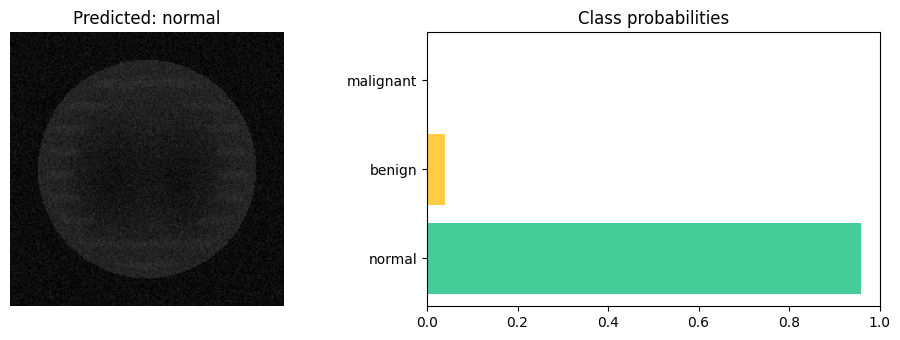

True class: benign


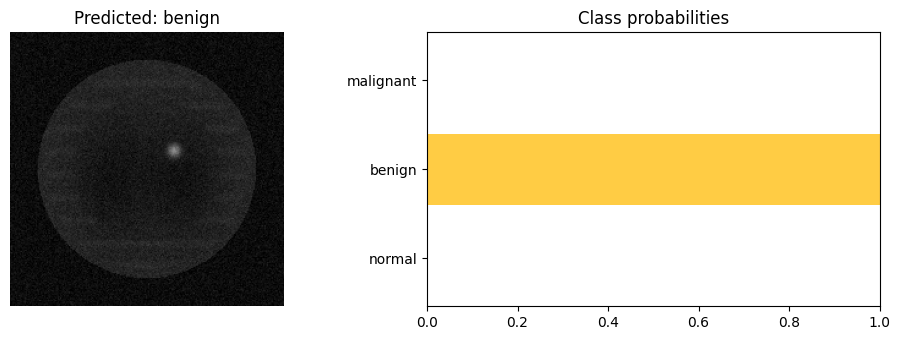

True class: malignant


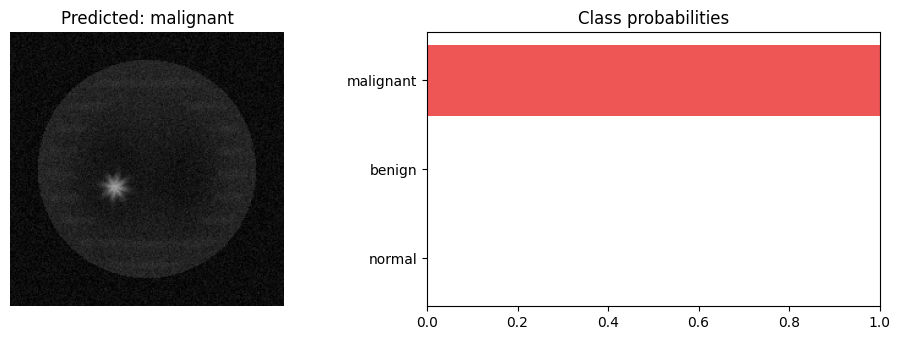

In [54]:
def predict_image(img_path, model=best_model, model_name=best_name, show=True):
    img = keras.utils.load_img(img_path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(img)[None, ...]
    arr = PREPROCESS[model_name](arr)
    probs = model.predict(arr, verbose=0)[0]
    pred = CLASS_NAMES[int(np.argmax(probs))]
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
        ax[0].imshow(img); ax[0].axis("off"); ax[0].set_title(f"Predicted: {pred}")
        ax[1].barh(CLASS_NAMES, probs, color=["#4c9", "#fc4", "#e55"]); ax[1].set_xlim(0, 1)
        ax[1].set_title("Class probabilities"); plt.tight_layout(); plt.show()
    return pred, probs

# Demo on random test images
for c in CLASS_NAMES:
    f = random.choice(os.listdir(os.path.join(TEST_DIR, c)))
    print("True class:", c)
    predict_image(os.path.join(TEST_DIR, c, f))

In [55]:
# Show misclassified test images of the best model
_, _, best_test_ds = get_datasets(None)           # raw pixels, then apply preprocessing manually
files = np.array(keras.utils.image_dataset_from_directory(
            TEST_DIR, labels="inferred", class_names=CLASS_NAMES, shuffle=False,
            image_size=IMG_SIZE, batch_size=BATCH_SIZE).file_paths)
y_true, probs = PROBS[best_name]
y_pred = probs.argmax(1)
wrong = np.where(y_true != y_pred)[0]
print(f"Misclassified: {len(wrong)} / {len(y_true)}")

n = min(10, len(wrong))
if n:
    fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
    for a, i in zip(axes.ravel(), np.random.choice(wrong, n, replace=False)):
        a.imshow(keras.utils.load_img(files[i])); a.axis("off")
        a.set_title(f"True: {CLASS_NAMES[y_true[i]]}\nPred: {CLASS_NAMES[y_pred[i]]}", fontsize=10, color="red")
    for a in axes.ravel()[n:]: a.axis("off")
    plt.tight_layout(); plt.show()

Found 180 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Found 60 files belonging to 3 classes.
Misclassified: 0 / 60


## 13. Conclusion

* A CNN trained from scratch gives a baseline; **transfer learning** typically converges faster and reaches higher scores because ImageNet features (edges, textures, shapes) are reused.
* The comparison table above ranks all five models on accuracy, precision, recall, F1 and ROC-AUC. Consider **model size / inference speed** too – MobileNetV2 and EfficientNetB0 are far lighter than VGG16.
* On a synthetic dataset, very high scores can occur because the generated patterns are easy to separate; this does **not** imply the models would perform similarly on real clinical images.

**Ideas for further work:** Grad-CAM visualisations, class-weighting, k-fold cross-validation, test-time augmentation, ensembling, hyper-parameter tuning (learning rate, unfrozen layers).

---
> ⚠️ **Reminder:** The data used here is synthetic and for educational purposes only. These models must **not** be used for diagnosis, screening, treatment decisions, or any medical purpose.